# Assignment 3: Routes & Loads — Interactive Demo & EDA

This notebook loads `last_3_digits` from `.env`, runs exploratory data analysis (EDA) on the assignment datasets, tests sample inputs alongside your personal parameters, and visualizes the DP tables, greedy mismatches, and road network graphs.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from data import load_seed_from_env, get_personal_params, PARCELS, COINS, HUBS, EDGES
from knapsack import knapsack_top_down, knapsack_bottom_up, reconstruct_knapsack
from coin_change import coin_change_dp, coin_change_greedy, find_greedy_mismatch
from graph_build import build_adj_list, build_adj_matrix
from bfs_dfs import bfs, dfs, components_and_cycle
from shortest_path import dijkstra, reconstruct_path
from mst import kruskal_mst

seed = load_seed_from_env('.env')
params = get_personal_params(seed)
W = params['W']
T = params['T']
start_hub = params['start_hub']

print(f'Personal Parameters from .env -> s={seed}, W={W}, T={T}, Start hub={start_hub}')

Personal Parameters from .env -> s=514, W=19, T=44, Start hub=C


## 1. Exploratory Data Analysis (EDA)
### 1A. Parcels Dataset (Problem A)

,Parcel,Weight,Value,Value_per_Weight
0,P1,2,3,1.50
1,P2,3,4,1.33
2,P3,4,5,1.25
3,P4,5,7,1.40
4,P5,6,8,1.33
5,P6,7,10,1.43
6,P7,9,13,1.44
7,P8,10,15,1.50


Summary Stats:


,Weight,Value,Value_per_Weight
count,8.00,8.00,8.00
mean,5.75,8.12,1.40
std,2.82,4.29,0.09
min,2.00,3.00,1.25
25%,3.75,4.75,1.33
50%,5.50,7.50,1.42
75%,7.50,10.75,1.46
max,10.00,15.00,1.50


Total weight of all parcels: 46 (Van capacity W = 19)
Total value of all parcels: 65


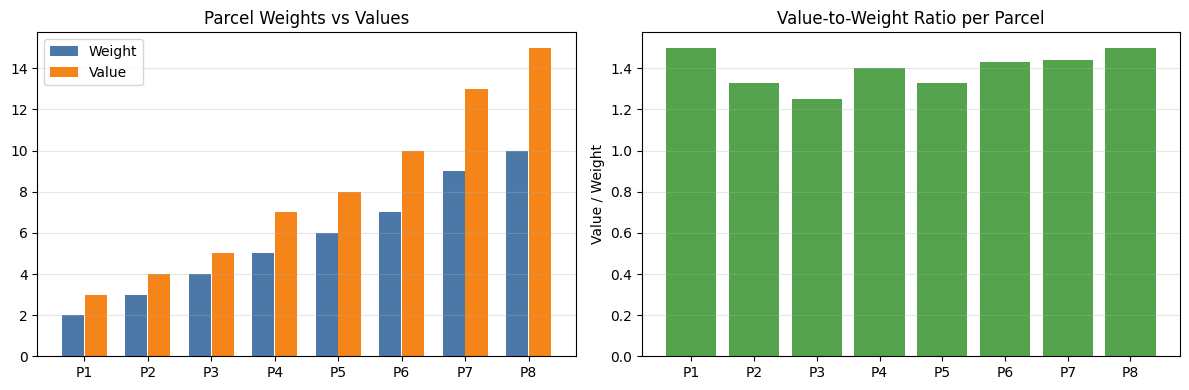

In [2]:
parcel_df = pd.DataFrame(PARCELS, columns=['Parcel', 'Weight', 'Value'])
parcel_df['Value_per_Weight'] = (parcel_df['Value'] / parcel_df['Weight']).round(2)
display(parcel_df)
print('Summary Stats:')
display(parcel_df[['Weight', 'Value', 'Value_per_Weight']].describe().round(2))
print(f"Total weight of all parcels: {parcel_df['Weight'].sum()} (Van capacity W = {W})")
print(f"Total value of all parcels: {parcel_df['Value'].sum()}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
x = range(len(parcel_df))
axes[0].bar([i - 0.18 for i in x], parcel_df['Weight'], width=0.35, label='Weight', color='#4C78A8')
axes[0].bar([i + 0.18 for i in x], parcel_df['Value'], width=0.35, label='Value', color='#F58518')
axes[0].set_xticks(list(x))
axes[0].set_xticklabels(parcel_df['Parcel'])
axes[0].set_title('Parcel Weights vs Values')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(parcel_df['Parcel'], parcel_df['Value_per_Weight'], color='#54A24B')
axes[1].set_title('Value-to-Weight Ratio per Parcel')
axes[1].set_ylabel('Value / Weight')
axes[1].grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

### 1B. Road Network EDA & Matrix Heatmap (Problems C–E)

Vertices V = 8, Edges E = 13, Density = 13/28 (46.4%)
Road lengths -> min=1, max=8, mean=3.92, total=51


,Hub,Degree,Neighbors,Min_Road,Max_Road,Sum_Incident_Lengths
0,A,2,"B, C",3,4,7
1,B,3,"A, C, D",1,4,7
2,C,4,"A, B, D, E",1,8,16
3,D,4,"B, C, E, F",2,6,14
4,E,4,"C, D, F, G",2,8,20
5,F,4,"D, E, G, H",2,6,16
6,G,3,"E, F, H",2,7,13
7,H,2,"F, G",4,5,9


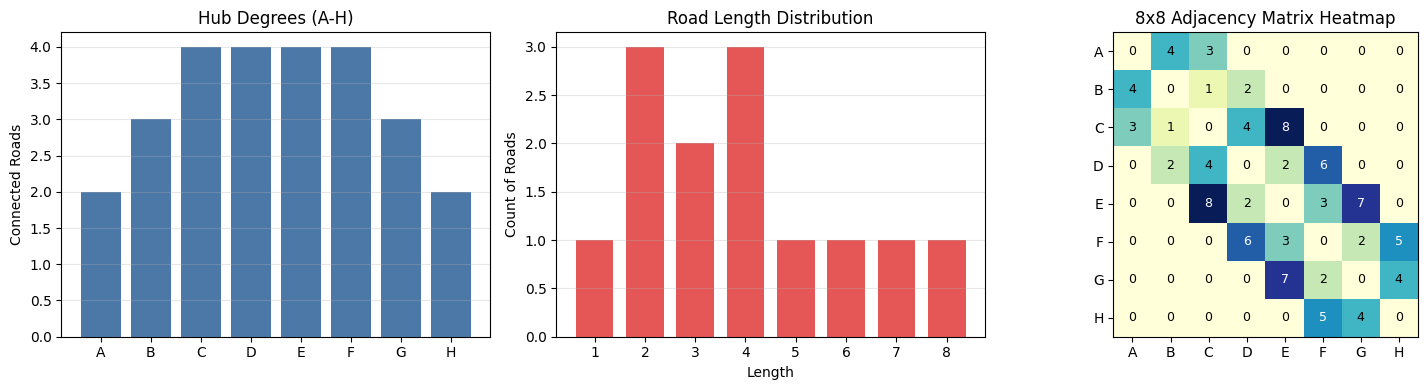

In [3]:
adj_list = build_adj_list(HUBS, EDGES)
adj_matrix = build_adj_matrix(HUBS, EDGES)

hub_stats = []
for h in HUBS:
    neighbors = [n for n, _ in adj_list[h]]
    lengths = [w for _, w in adj_list[h]]
    hub_stats.append({
        'Hub': h,
        'Degree': len(neighbors),
        'Neighbors': ', '.join(neighbors),
        'Min_Road': min(lengths),
        'Max_Road': max(lengths),
        'Sum_Incident_Lengths': sum(lengths)
    })
hub_df = pd.DataFrame(hub_stats)
edge_df = pd.DataFrame(EDGES, columns=['Hub1', 'Hub2', 'Length'])

V, E = len(HUBS), len(EDGES)
max_possible = V * (V - 1) // 2
print(f'Vertices V = {V}, Edges E = {E}, Density = {E}/{max_possible} ({E/max_possible:.1%})')
print(f"Road lengths -> min={edge_df['Length'].min()}, max={edge_df['Length'].max()}, mean={edge_df['Length'].mean():.2f}, total={edge_df['Length'].sum()}")
display(hub_df)

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].bar(hub_df['Hub'], hub_df['Degree'], color='#4C78A8')
axes[0].set_title('Hub Degrees (A-H)')
axes[0].set_ylabel('Connected Roads')
axes[0].grid(axis='y', alpha=0.3)

axes[1].hist(edge_df['Length'], bins=range(1, 10), align='left', rwidth=0.75, color='#E45756')
axes[1].set_title('Road Length Distribution')
axes[1].set_xlabel('Length')
axes[1].set_ylabel('Count of Roads')
axes[1].set_xticks(range(1, 9))
axes[1].grid(axis='y', alpha=0.3)

im = axes[2].imshow(adj_matrix, cmap='YlGnBu')
axes[2].set_xticks(range(V)); axes[2].set_xticklabels(HUBS)
axes[2].set_yticks(range(V)); axes[2].set_yticklabels(HUBS)
axes[2].set_title('8x8 Adjacency Matrix Heatmap')
for i in range(V):
    for j in range(V):
        val = adj_matrix[i][j]
        axes[2].text(j, i, str(val), ha='center', va='center', color='white' if val >= 5 else 'black', fontsize=9)
plt.tight_layout()
plt.show()

## 2. Sample Inputs & Outputs (Comparison for Demo)
Testing multiple sample seeds/edge cases alongside your `.env` seed (`514`).

In [4]:
sample_seeds = [seed, 605, 0, 123]
dp_rows = []
graph_rows = []

for s_val in sample_seeds:
    p = get_personal_params(s_val)
    val_td = knapsack_top_down(PARCELS, p['W'])
    val_bu, tbl = knapsack_bottom_up(PARCELS, p['W'])
    chosen_p = [item[0] for item in reconstruct_knapsack(PARCELS, p['W'], tbl)]
    c_dp, c_dp_list = coin_change_dp(COINS, p['T'])
    c_gr, c_gr_list = coin_change_greedy(COINS, p['T'])
    dp_rows.append({
        'Seed_s': s_val, 'W': p['W'], 'Knapsack_Val': val_bu,
        'Parcels': ', '.join(chosen_p), 'T': p['T'],
        'DP_Coins': f'{c_dp} {c_dp_list}', 'Greedy_Coins': f'{c_gr} {c_gr_list}',
        'Match': c_dp == c_gr
    })
    b_ord, b_dist = bfs(adj_list, p['start_hub'])
    d_ord = dfs(adj_list, p['start_hub'])
    d_dist, d_par = dijkstra(adj_list, p['start_hub'])
    d_path = reconstruct_path(d_par, p['start_hub'], 'H')
    graph_rows.append({
        'Seed_s': s_val, 'Start': p['start_hub'],
        'BFS_Order': '->'.join(b_ord), 'Hops_to_H': b_dist['H'],
        'DFS_Order': '->'.join(d_ord), 'Dijkstra_to_H': d_dist['H'],
        'Shortest_Path_H': '->'.join(d_path)
    })

print('Sample Inputs & Outputs — Problems A & B (DP):')
display(pd.DataFrame(dp_rows))
print('Sample Inputs & Outputs — Problems C & D (Graphs):')
display(pd.DataFrame(graph_rows))

# Extra small edge-case checks for Problem B (amount=6 mismatch) and Problem A (W=5)
print('Edge Case Check — Knapsack W=5:', reconstruct_knapsack(PARCELS, 5, knapsack_bottom_up(PARCELS, 5)[1]))
print('Edge Case Check — Coin Change T=6 -> DP:', coin_change_dp(COINS, 6), '| Greedy:', coin_change_greedy(COINS, 6))

Sample Inputs & Outputs — Problems A & B (DP):


,Seed_s,W,Knapsack_Val,Parcels,T,DP_Coins,Greedy_Coins,Match
0,514,19,28,"P1, P6, P8",44,"6 [4, 4, 9, 9, 9, 9]","6 [9, 9, 9, 9, 4, 4]",True
1,605,20,29,"P1, P2, P4, P8",35,"5 [4, 4, 9, 9, 9]","5 [9, 9, 9, 4, 4]",True
2,0,15,22,"P1, P2, P8",30,"4 [3, 9, 9, 9]","4 [9, 9, 9, 3]",True
3,123,18,26,"P1, P6, P7",33,"5 [3, 3, 9, 9, 9]","6 [9, 9, 9, 4, 1, 1]",False


Sample Inputs & Outputs — Problems C & D (Graphs):


,Seed_s,Start,BFS_Order,Hops_to_H,DFS_Order,Dijkstra_to_H,Shortest_Path_H
0,514,C,C->A->B->D->E->F->G->H,3,C->A->B->D->E->F->G->H,13,C->B->D->E->F->H
1,605,F,F->D->E->G->H->B->C->A,1,F->D->B->A->C->E->G->H,5,F->H
2,0,A,A->B->C->D->E->F->G->H,4,A->B->C->D->E->F->G->H,16,A->B->D->E->F->H
3,123,D,D->B->C->E->F->A->G->H,2,D->B->A->C->E->F->G->H,10,D->E->F->H


Edge Case Check — Knapsack W=5: [('P1', 2, 3), ('P2', 3, 4)]
Edge Case Check — Coin Change T=6 -> DP: (2, [3, 3]) | Greedy: (3, [4, 1, 1])


## 3. Problem A Visualization: 0/1 Knapsack DP Table & Backtracking Path

W = 19 -> Max Value = 28, Chosen = [('P1', 2, 3), ('P6', 7, 10), ('P8', 10, 15)]


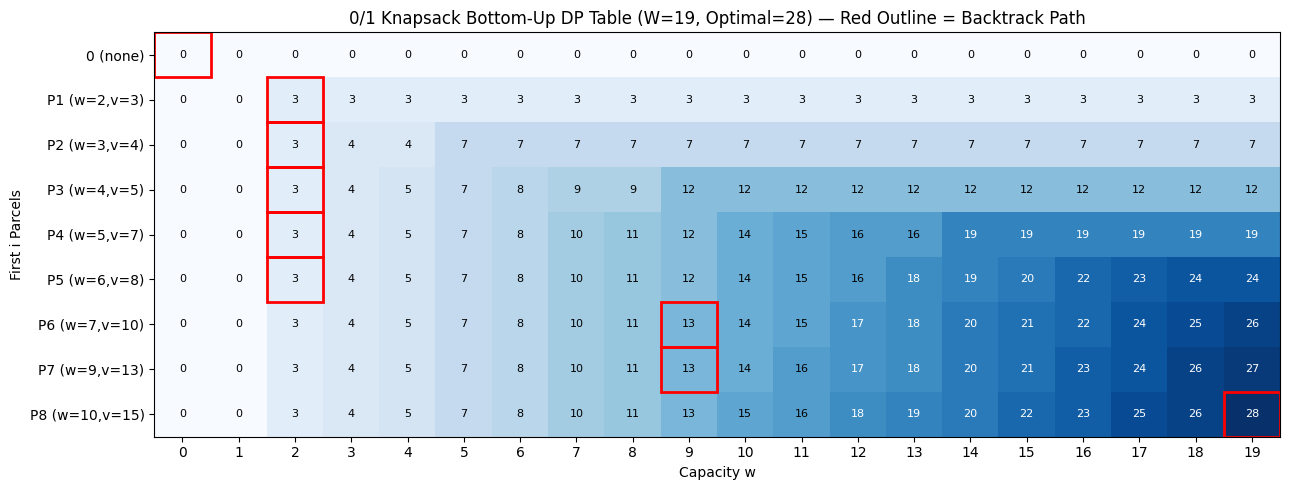

In [5]:
max_val, dp_table = knapsack_bottom_up(PARCELS, W)
chosen_parcels = reconstruct_knapsack(PARCELS, W, dp_table)
print(f'W = {W} -> Max Value = {max_val}, Chosen = {chosen_parcels}')

# Trace the exact (i, w) cells visited during reconstruction
trace_cells = set()
ti, tw = len(PARCELS), W
while ti >= 0 and tw >= 0:
    trace_cells.add((ti, tw))
    if ti == 0 or tw == 0:
        break
    if dp_table[ti][tw] != dp_table[ti - 1][tw]:
        tw -= PARCELS[ti - 1][1]
    ti -= 1

fig, ax = plt.subplots(figsize=(13, 5))
ax.imshow(dp_table, cmap='Blues', aspect='auto')
row_labels = ['0 (none)'] + [f'{p[0]} (w={p[1]},v={p[2]})' for p in PARCELS]
ax.set_yticks(range(len(PARCELS) + 1)); ax.set_yticklabels(row_labels)
ax.set_xticks(range(W + 1)); ax.set_xticklabels(range(W + 1))
ax.set_xlabel('Capacity w'); ax.set_ylabel('First i Parcels')
ax.set_title(f'0/1 Knapsack Bottom-Up DP Table (W={W}, Optimal={max_val}) — Red Outline = Backtrack Path')

for r in range(len(PARCELS) + 1):
    for c in range(W + 1):
        val = dp_table[r][c]
        ax.text(c, r, str(val), ha='center', va='center', color='white' if val > max_val * 0.6 else 'black', fontsize=8)
        if (r, c) in trace_cells:
            rect = plt.Rectangle((c - 0.5, r - 0.5), 1, 1, fill=False, edgecolor='red', linewidth=2)
            ax.add_patch(rect)
plt.tight_layout()
plt.show()

## 4. Problem B Visualization: Coin Change DP vs Greedy (`1..T`)

Amounts in 1..44 where Greedy fails to match DP (5 cases):


,Amount,DP_Count,DP_Coins,Greedy_Count,Greedy_Coins
0,6,2,"[3, 3]",3,"[4, 1, 1]"
1,15,3,"[3, 3, 9]",4,"[9, 4, 1, 1]"
2,24,4,"[3, 3, 9, 9]",5,"[9, 9, 4, 1, 1]"
3,33,5,"[3, 3, 9, 9, 9]",6,"[9, 9, 9, 4, 1, 1]"
4,42,6,"[3, 3, 9, 9, 9, 9]",7,"[9, 9, 9, 9, 4, 1, 1]"


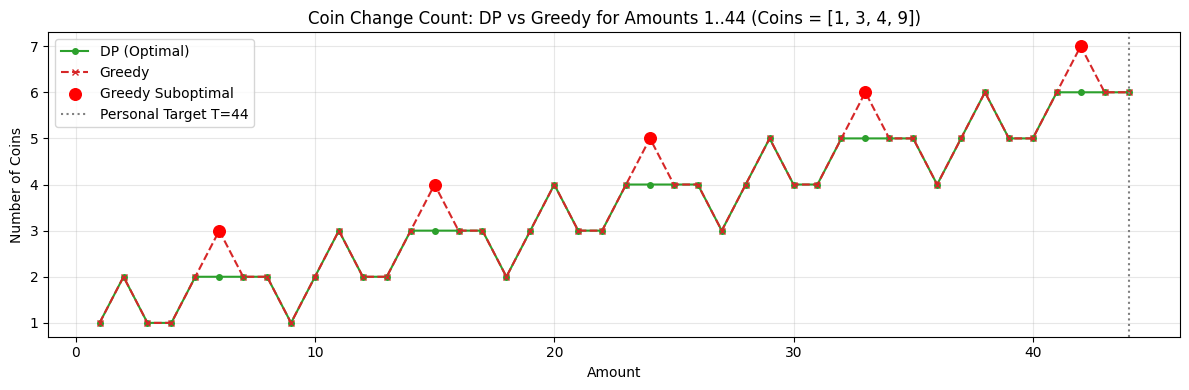

In [6]:
amounts = list(range(1, T + 1))
dp_counts, gr_counts, mismatches = [], [], []

for amt in amounts:
    d_cnt, d_used = coin_change_dp(COINS, amt)
    g_cnt, g_used = coin_change_greedy(COINS, amt)
    dp_counts.append(d_cnt)
    gr_counts.append(g_cnt)
    if d_cnt != g_cnt:
        mismatches.append({'Amount': amt, 'DP_Count': d_cnt, 'DP_Coins': d_used, 'Greedy_Count': g_cnt, 'Greedy_Coins': g_used})

mismatch_df = pd.DataFrame(mismatches)
print(f'Amounts in 1..{T} where Greedy fails to match DP ({len(mismatch_df)} cases):')
display(mismatch_df.head(10))

plt.figure(figsize=(12, 4))
plt.plot(amounts, dp_counts, marker='o', markersize=4, label='DP (Optimal)', color='#2CA02C')
plt.plot(amounts, gr_counts, marker='x', markersize=5, linestyle='--', label='Greedy', color='#D62728')
if len(mismatch_df) > 0:
    plt.scatter(mismatch_df['Amount'], mismatch_df['Greedy_Count'], color='red', s=70, zorder=5, label='Greedy Suboptimal')
plt.axvline(T, color='gray', linestyle=':', label=f'Personal Target T={T}')
plt.title(f'Coin Change Count: DP vs Greedy for Amounts 1..{T} (Coins = {COINS})')
plt.xlabel('Amount'); plt.ylabel('Number of Coins')
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

## 5. Problems C, D, E Visualizations: Network, Dijkstra Shortest Path & Kruskal MST

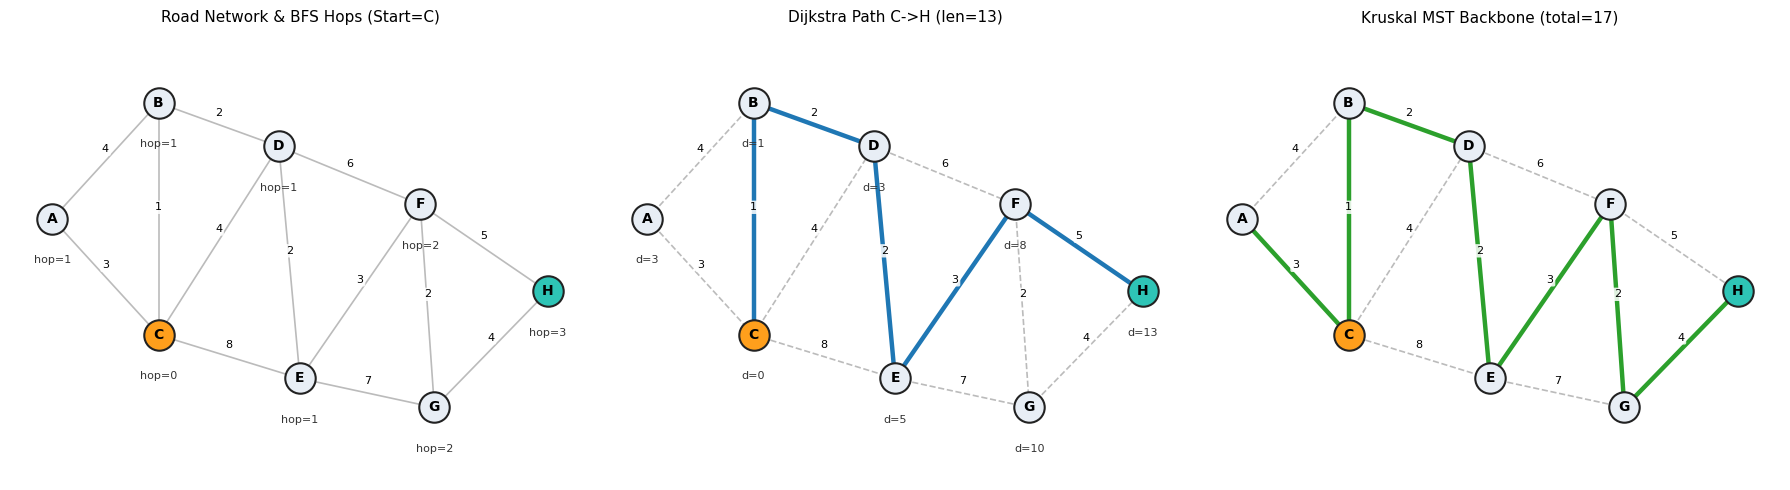

In [7]:
pos = {
    'A': (0.0, 1.5), 'B': (1.5, 2.3), 'C': (1.5, 0.7),
    'D': (3.2, 2.0), 'E': (3.5, 0.4), 'F': (5.2, 1.6),
    'G': (5.4, 0.2), 'H': (7.0, 1.0)
}

bfs_order, hop_dist = bfs(adj_list, start_hub)
dijk_dist, dijk_parent = dijkstra(adj_list, start_hub)
path_h = reconstruct_path(dijk_parent, start_hub, 'H')
path_edges = set((path_h[i], path_h[i+1]) for i in range(len(path_h) - 1))
mst_edges, mst_total = kruskal_mst(HUBS, EDGES)
mst_set = set((u, v) for u, v, _ in mst_edges)

def draw_panel(ax, title, highlight_edges, highlight_color, node_labels):
    for u, v, w in EDGES:
        x1, y1 = pos[u]; x2, y2 = pos[v]
        is_hi = (u, v) in highlight_edges or (v, u) in highlight_edges
        ax.plot([x1, x2], [y1, y2],
                color=highlight_color if is_hi else '#BBBBBB',
                linewidth=3.2 if is_hi else 1.2,
                linestyle='-' if (is_hi or not highlight_edges) else '--', zorder=1)
        ax.text((x1 + x2) / 2, (y1 + y2) / 2 + 0.08, str(w),
                fontsize=8, ha='center', va='center',
                bbox=dict(boxstyle='round,pad=0.15', fc='white', ec='none', alpha=0.85))
    for h in HUBS:
        x, y = pos[h]
        fc = '#FF9F1C' if h == start_hub else ('#2EC4B6' if h == 'H' else '#E8EEF5')
        ax.scatter([x], [y], s=480, color=fc, edgecolors='#222222', linewidth=1.5, zorder=3)
        ax.text(x, y, h, fontsize=10, fontweight='bold', ha='center', va='center', zorder=4)
        ax.text(x, y - 0.25, node_labels[h], fontsize=8, ha='center', va='top', color='#333333')
    ax.set_title(title, fontsize=11)
    ax.set_xlim(-0.6, 7.6); ax.set_ylim(-0.3, 2.8); ax.axis('off')

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
draw_panel(axes[0], f'Road Network & BFS Hops (Start={start_hub})', set(), '#555555', {h: f'hop={hop_dist[h]}' for h in HUBS})
draw_panel(axes[1], f'Dijkstra Path {start_hub}->H (len={dijk_dist["H"]})', path_edges, '#1F77B4', {h: f'd={dijk_dist[h]}' for h in HUBS})
draw_panel(axes[2], f'Kruskal MST Backbone (total={mst_total})', mst_set, '#2CA02C', {h: '' for h in HUBS})
plt.tight_layout()
plt.show()